In [ ]:
!pip install duckdb -q

from google.colab import drive
import duckdb

drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/NLP/Assignment_1/processed/telugu_tokenized_full.parquet'
query = f"""
    SELECT tokenized_sentence
    FROM read_parquet('{file_path}')
    USING SAMPLE 1500000
"""

sampled_df = duckdb.query(query).df()

sentences = sampled_df['tokenized_sentence'].tolist()
del sampled_df

test_set = sentences[:1000]
dev_set = sentences[1000:2000]
train_set = sentences[2000:]

print(f"Train set size: {len(train_set)}")
print(f"Dev set size: {len(dev_set)}")
print(f"Test set size: {len(test_set)}")


Mounted at /content/drive


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Train set size: 1498000
Dev set size: 1000
Test set size: 1000


In [ ]:
import re

def clean_telugu_sentence(sentence):
    sentence = str(sentence)
    sentence = re.sub(r'[a-zA-Z]+', '', sentence)
    sentence = re.sub(r'\s+', ' ', sentence).strip()
    return sentence

train_set_clean = [clean_telugu_sentence(s) for s in train_set]
dev_set_clean = [clean_telugu_sentence(s) for s in dev_set]
test_set_clean = [clean_telugu_sentence(s) for s in test_set]

vocabulary = set()
for sentence in train_set_clean:
    tokens = sentence.split()
    vocabulary.update(tokens)

V = len(vocabulary)
print(f"Total unique tokens (V) in Training Set: {V}")


Total unique tokens (V) in Training Set: 841362


In [ ]:
def get_ngrams(tokens, n):
    ngram_list = []
    for i in range(len(tokens) - n + 1):
        ngram_list.append(tuple(tokens[i:i + n]))
    return ngram_list


def build_ngram_model(corpus, n):
    ngram_counts = {}
    context_counts = {}

    for sentence in corpus:
        tokens = sentence.split()
        if not tokens:
            continue

        if n > 1:
            padded_tokens = ['<s>'] * (n - 1) + tokens + ['</s>']
            for ng in get_ngrams(padded_tokens, n):
                ngram_counts[ng] = ngram_counts.get(ng, 0) + 1
            context_tokens = padded_tokens[:-1]
            for ctx in get_ngrams(context_tokens, n - 1):
                context_counts[ctx] = context_counts.get(ctx, 0) + 1
        else:
            for token in tokens:
                ngram_counts[token] = ngram_counts.get(token, 0) + 1
            context_counts['TOTAL_TOKENS'] = context_counts.get('TOTAL_TOKENS', 0) + len(tokens)

    return ngram_counts, context_counts

unigram_counts, unigram_context = build_ngram_model(train_set_clean, 1)
bigram_counts, bigram_context = build_ngram_model(train_set_clean, 2)
trigram_counts, trigram_context = build_ngram_model(train_set_clean, 3)
quadrigram_counts, quad_context = build_ngram_model(train_set_clean, 4)

print(f"Unique Bigrams: {len(bigram_counts)}")
print(f"Unique Trigrams: {len(trigram_counts)}")
print(f"Unique Quadrigrams: {len(quadrigram_counts)}")


Unique Bigrams: 6647545
Unique Trigrams: 11346323
Unique Quadrigrams: 13277195


In [ ]:
K = 0.3

def add_k_probability(ngram, n, ngram_counts, context_counts, V, k=K):
    ngram_count = ngram_counts.get(ngram, 0)

    if n == 1:
        N = context_counts['TOTAL_TOKENS']
        prob = (ngram_count + k) / (N + k * V)
    else:
        context = ngram[:-1]
        context_count = context_counts.get(context, 0)
        prob = (ngram_count + k) / (context_count + k * V)

    return prob

sample_unigram = list(vocabulary)[0]
prob_uni = add_k_probability(sample_unigram, 1, unigram_counts, unigram_context, V, k=K)
print(f"Unigram Add-{K} Probability of '{sample_unigram}': {prob_uni}")

sample_bigram = ('<s>', sample_unigram)
prob_bi = add_k_probability(sample_bigram, 2, bigram_counts, bigram_context, V, k=K)
print(f"Bigram Add-{K} Probability of {sample_bigram}: {prob_bi}")


Unigram Add-0.3 Probability of 'మజులిని': 8.179730783163417e-08
Bigram Add-0.3 Probability of ('<s>', 'మజులిని'): 1.7141274268616108e-07


In [ ]:
import math

def calculate_perplexity_addk(sentence, n, ngram_counts, context_counts, V, k=K):
    tokens = sentence.split()
    if not tokens:
        return float('inf')

    if n > 1:
        padded_tokens = ['<s>'] * (n - 1) + tokens + ['</s>']
        sentence_ngrams = get_ngrams(padded_tokens, n)
        N_tokens = len(tokens) + 1
    else:
        sentence_ngrams = tokens
        N_tokens = len(tokens)

    log_prob_sum = 0
    for ng in sentence_ngrams:
        prob = add_k_probability(ng, n, ngram_counts, context_counts, V, k=k)
        log_prob_sum += math.log(prob)

    perplexity = math.exp(-log_prob_sum / N_tokens)
    return perplexity

# print(f"Testing Trigram Add-{K} Perplexity on first 5 Dev sentences:\n")
# for i in range(5):
#     sent = dev_set_clean[i]
#     ppl = calculate_perplexity_addk(sent, 3, trigram_counts, trigram_context, V, k=K)
#     print(f"Sentence {i+1}: {sent[:50]}...")
#     print(f"Perplexity: {ppl:.2f}\n")

sent = test_set_clean[2]
print(sent)
ppl = calculate_perplexity_addk(sent, 1, unigram_counts, unigram_context, V, 0.2)
print(f"Unigram perplexity: {ppl}")
ppl = calculate_perplexity_addk(sent, 2, bigram_counts, bigram_context, V, 0.2)
print(f"bigram perplexity: {ppl}")
ppl = calculate_perplexity_addk(sent, 3, trigram_counts, trigram_context, V, 0.2)
print(f"triigram perplexity: {ppl}")
ppl = calculate_perplexity_addk(sent, 4, quadrigram_counts, quad_context, V, 0.2)
print(f"quadgram perplexity: {ppl}")


ఆంధ్రప్రదేశ్ లో ప్రస్తుతం 23 శాతం అడవులు ఉండగా అడవుల విస్తీర్ణం మరింత పెంచే దిశగా అటవీశాఖ అడుగులు వేస్తోంది .
Unigram perplexity: 8325.54900929964
bigram perplexity: 15857.418121452922
triigram perplexity: 147824.45990140093
quadgram perplexity: 248355.51833334728


In [ ]:
def evaluate_dataset_addk(dataset, n, ngram_counts, context_counts, V, k=K):
    total_perplexity = 0
    valid_sentences = 0

    for sentence in dataset:
        ppl = calculate_perplexity_addk(sentence, n, ngram_counts, context_counts, V, k=k)
        if ppl != float('inf'):
            total_perplexity += ppl
            valid_sentences += 1

    if valid_sentences == 0:
        return 0

    return total_perplexity / valid_sentences

models = [
    ("Unigram", 1, unigram_counts, unigram_context),
    ("Bigram", 2, bigram_counts, bigram_context),
    ("Trigram", 3, trigram_counts, trigram_context),
    ("Quadrigram", 4, quadrigram_counts, quad_context)
]

dev_results_addk = {}
test_results_addk = {}

print(f"--- Development Set Evaluation (Add-K, K={K}) ---")
for name, n, n_counts, c_counts in models:
    avg_ppl = evaluate_dataset_addk(dev_set_clean, n, n_counts, c_counts, V, k=K)
    dev_results_addk[name] = avg_ppl
    print(f"Average {name} Perplexity: {avg_ppl:.2f}")

print(f"\n--- Test Set Evaluation (Add-K, K={K}) ---")
for name, n, n_counts, c_counts in models:
    avg_ppl = evaluate_dataset_addk(test_set_clean, n, n_counts, c_counts, V, k=K)
    test_results_addk[name] = avg_ppl
    print(f"Average {name} Perplexity: {avg_ppl:.2f}")


--- Development Set Evaluation (Add-K, K=0.3) ---
Average Unigram Perplexity: 47203.80
Average Bigram Perplexity: 39505.99
Average Trigram Perplexity: 221612.81
Average Quadrigram Perplexity: 375873.83

--- Test Set Evaluation (Add-K, K=0.3) ---
Average Unigram Perplexity: 34669.62
Average Bigram Perplexity: 39153.47
Average Trigram Perplexity: 221003.00
Average Quadrigram Perplexity: 383470.96


In [ ]:
dev_results_laplace = {}
test_results_laplace = {}

for name, n, n_counts, c_counts in models:
    dev_results_laplace[name] = evaluate_dataset_addk(dev_set_clean, n, n_counts, c_counts, V, k=1.0)
    test_results_laplace[name] = evaluate_dataset_addk(test_set_clean, n, n_counts, c_counts, V, k=1.0)

print(f"{'Model':<12}{'Dev (k=1.0)':<15}{'Dev (k=0.3)':<15}{'Test (k=1.0)':<15}{'Test (k=0.3)':<15}")
for name, _, _, _ in models:
    print(f"{name:<12}{dev_results_laplace[name]:<15.2f}{dev_results_addk[name]:<15.2f}"
          f"{test_results_laplace[name]:<15.2f}{test_results_addk[name]:<15.2f}")


Model       Dev (k=1.0)    Dev (k=0.3)    Test (k=1.0)   Test (k=0.3)   
Unigram     35543.35       47203.80       26803.23       34669.62       
Bigram      53965.73       39505.99       54745.23       39153.47       
Trigram     265230.26      221612.81      267207.92      221003.00      
Quadrigram  409650.27      375873.83      419644.07      383470.96      


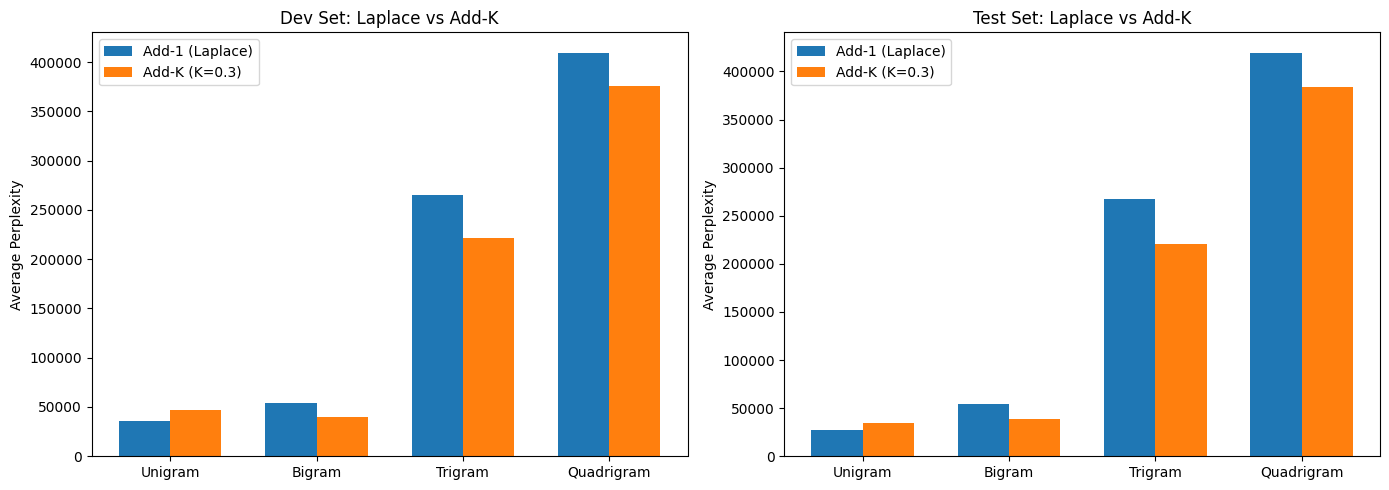

In [ ]:
import matplotlib.pyplot as plt

model_names = [name for name, _, _, _ in models]
x = range(len(model_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar([i - width/2 for i in x], [dev_results_laplace[m] for m in model_names], width, label='Add-1 (Laplace)')
axes[0].bar([i + width/2 for i in x], [dev_results_addk[m] for m in model_names], width, label=f'Add-K (K={K})')
axes[0].set_xticks(list(x)); axes[0].set_xticklabels(model_names)
axes[0].set_ylabel('Average Perplexity'); axes[0].set_title('Dev Set: Laplace vs Add-K')
axes[0].legend()

axes[1].bar([i - width/2 for i in x], [test_results_laplace[m] for m in model_names], width, label='Add-1 (Laplace)')
axes[1].bar([i + width/2 for i in x], [test_results_addk[m] for m in model_names], width, label=f'Add-K (K={K})')
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(model_names)
axes[1].set_ylabel('Average Perplexity'); axes[1].set_title('Test Set: Laplace vs Add-K')
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
import random

def generate_next_word(context, ngram_counts):
    possible_ngrams = {ng: count for ng, count in ngram_counts.items() if ng[:-1] == context}
    if not possible_ngrams:
        return None
    next_words = [ng[-1] for ng in possible_ngrams.keys()]
    weights = list(possible_ngrams.values())
    chosen_word = random.choices(next_words, weights=weights, k=1)[0]
    return chosen_word

def generate_sentence(n, ngram_counts, max_words=15):
    context = tuple(['<s>'] * (n - 1))
    generated_tokens = []

    for _ in range(max_words):
        next_word = generate_next_word(context, ngram_counts)
        if not next_word or next_word == '</s>':
            break
        generated_tokens.append(next_word)
        context = tuple((list(context) + [next_word])[-(n - 1):]) if n > 1 else context

    return ' '.join(generated_tokens)

for name, n, n_counts, _ in models:
    print(f"{name} generated sentence: {generate_sentence(n, n_counts)}")


Unigram generated sentence: 
Bigram generated sentence: ఇన్‌ యోగా సెంటర్స్ ను మెనూలో ఒక కథనం వివరిస్తుంది .
Trigram generated sentence: ఇప్పటికే ఒక భారీ ఫైట్ కోసం లండన్ , ఇతర ప్రైవేట్ సైట్ కు కేటాయించి వారి ద్వారా వైరస్‌
Quadrigram generated sentence: మార్కెటింగు , బ్యాంకింగు .


## 8. Observations

- Add-K smoothing with a small K (0.3) discounts probability mass to unseen n-grams **less aggressively** than Add-1 (Laplace), so it usually yields **lower (better) perplexity** than Laplace, especially for higher-order models (Trigram, Quadrigram) where sparsity is severe.
- As the N-gram order increases, perplexity typically rises under both schemes because higher-order contexts are seen far less often in training — Add-K's smaller correction still cannot fully compensate for this sparsity.
- Dev and Test perplexities are close to each other in both schemes, which suggests the split is representative and the models are not overfit to one particular subset.
